# Hafta 6 · Sorularla Bölmek: Ağaçlar ve Topluluklar

**Ekonomi ve Finansta Makine Öğrenmesi** · Prof. Dr. Mehmet Songur · Dicle Üniversitesi

[![Colab'da aç](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mehmetsongur/Machine-Learning-in-Economics-and-Finance/blob/main/code/Hafta06_Agaclar_ve_SHAP.ipynb)

**Haftanın konusu:** Ağaçlar ve topluluk yöntemleri (rassal orman, boosting); yorumlanabilirlik (SHAP)

Bu defter, Hafta 6 ders notundaki ve slaytlarındaki şu şekil ve tabloları üretir:

- **Şekil 1 (1.1):** Veriden kurulan derinliği 3 olan karar ağacı
- **Şekil 2 (1.2):** Derinlik ve aşırı uyum; derinliğin çapraz doğrulamayla seçimi
- **Tablo (1.3):** Tek ağacın kararsızlığı (5 bootstrap örneklemi)
- **Şekil 3 ve tablo (2.1):** Rassal orman ve bagging
- **Şekil 4–5 (3.2–3.3):** Boosting, öğrenme oranı, ağaç sayısının seçimi ve beş modelin karşılaştırması
- **Şekil 6–11 (4.2–4.4):** SHAP: toplama özelliği, iki başvuranın açıklaması, genel önem, bağımlılık ve etkileşim

Tüm sayılar yapay (simüle edilmiş) veriye dayanır. Rastgele sayı üreticisinin tohumu sabit olduğu için hücreler **yukarıdan aşağıya sırayla** çalıştırıldığında sonuçlar ders materyalindeki değerlerle birebir aynı çıkar. Hücreleri atlarsanız ya da sırasını değiştirirseniz sayılar biraz farklılaşabilir; yorumlar değişmez.

Slaytlar: [Hafta 6 (PDF)](https://www.songurmehmet.com/assets/dersler/ml/Hafta06_Slaytlar.pdf)  
Kod MIT lisansıyla paylaşılmıştır; ayrıntı için deponun `code/LICENSE` dosyasına bakın.

## Kurulum

Hafta 5’in kredi dünyası, altı değişken aynen. Fark: gerçek risk artık doğrusal değil.
- borç/gelir 0,7’yi aşınca risk **sıçrıyor** (eşik),
- önceki gecikme borcu yüksek olanlarda çok daha tehlikeli (**etkileşim**),
- işe yeni başlayanlar riskli,
- yaşın etkisi **U biçimli** (çok genç ve çok yaşlılar daha riskli).

Model 3.000 başvuruyla eğitiliyor, 20.000 yeni başvuruda test ediliyor. Defterin tamamı Colab’da yaklaşık bir dakika sürer. SHAP kütüphanesi Colab’da yüklü değilse ilk hücre kurar.

In [1]:
try:
    import shap
except ImportError:
    !pip install -q shap
    import shap

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(2026)   # tohum: sonuçlar ders notuyla aynı çıkar
ADLAR = ['Borç/gelir', 'Önceki gecikme', 'Gelir', 'Çalışma süresi', 'Kart harcaması/gelir', 'Yaş']

def ciz(n):
    X = rng.normal(size=(n, 6))
    X[:, 1] = (rng.random(n) < 0.15).astype(float)            # önceki gecikme: 0/1, %15
    X[:, 4] = 0.4 * X[:, 0] + np.sqrt(1 - 0.16) * X[:, 4]      # kart harcaması borçla ilişkili
    X[:, 5] = 0.5 * X[:, 3] + np.sqrt(0.75) * X[:, 5]          # yaş çalışma süresiyle ilişkili
    b, g, gel, cal, kart, yas = X.T
    lo = (-2.9 + 1.5 * (b > 0.7)                 # eşik etkisi
          + 0.5 * g + 1.2 * g * (b > 0)          # etkileşim: gecikme, borcu yüksek olanlarda daha tehlikeli
          - 0.5 * gel                            # doğrusal
          + 0.8 * (cal < -0.8)                   # işe yeni başlayanlar
          + 0.35 * kart                          # doğrusal
          + 0.45 * (yas ** 2 - 1))               # U biçimi
    p = 1 / (1 + np.exp(-lo))
    return X, (rng.random(n) < p).astype(int), p

X_egt, y_egt, _ = ciz(3000)
X_tst, y_tst, p_gercek = ciz(20000)
kf = KFold(5, shuffle=True, random_state=1)
print(f'Temerrüt oranı  eğitim: %{100*y_egt.mean():.1f}   test: %{100*y_tst.mean():.1f}')
print(f'Gerçek olasılıklarla ulaşılabilecek en yüksek AUC: {roc_auc_score(y_tst, p_gercek):.3f}')

logit = LogisticRegression(C=1e6, max_iter=2000).fit(X_egt, y_egt)    # Hafta 5'in modeli
print(f'Lojistik regresyon test AUC: {roc_auc_score(y_tst, logit.predict_proba(X_tst)[:, 1]):.3f}')

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Temerrüt oranı  eğitim: %16.6   test: %15.7
Gerçek olasılıklarla ulaşılabilecek en yüksek AUC: 0.818
Lojistik regresyon test AUC: 0.735


Beklenen: temerrüt oranı %16.6 / %15.7; ulaşılabilecek en yüksek AUC 0,818; lojistik regresyon 0,735.

## 1. Karar ağacı

### 1.1 Veriden bir soru dizisi (Şekil 1)

Derinliği 3 olan, her yaprakta en az 100 kişi bulunan bir ağaç. Yapraklardaki `value` satırı, o gruptaki ödeyen ve temerrüt eden oranlarını gösterir.

Test AUC  derinlik 2: 0.699   derinlik 3: 0.733


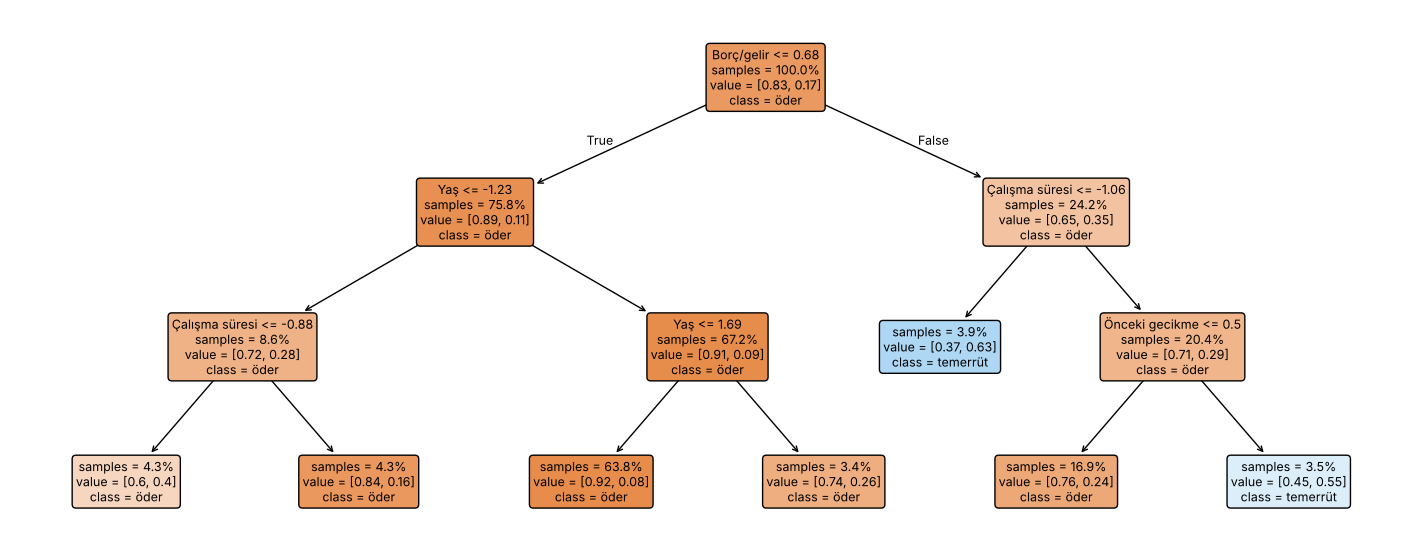

In [2]:
t2 = DecisionTreeClassifier(max_depth=2, min_samples_leaf=100, random_state=0).fit(X_egt, y_egt)
t3 = DecisionTreeClassifier(max_depth=3, min_samples_leaf=100, random_state=0).fit(X_egt, y_egt)
print(f'Test AUC  derinlik 2: {roc_auc_score(y_tst, t2.predict_proba(X_tst)[:, 1]):.3f}   '
      f'derinlik 3: {roc_auc_score(y_tst, t3.predict_proba(X_tst)[:, 1]):.3f}')

plt.figure(figsize=(18, 7))
plot_tree(t3, feature_names=ADLAR, class_names=['öder', 'temerrüt'], filled=True, proportion=True,
          impurity=False, rounded=True, precision=2, fontsize=9)
plt.show()

Ağacın üç bulgusu: ilk soru borç/gelir ≤ 0,68 (gerçek eşik 0,7); gecikme sorusu yalnızca borcu yüksek olanlara soruluyor (etkileşim); yaş sol dalda iki kez soruluyor, hem çok gençler hem çok yaşlılar riskli (U biçimi).

### 1.2 Derinlik ve aşırı uyum (Şekil 2)

Derinliği Hafta 3’teki gibi eğitim verisi içinde 5 katlı çapraz doğrulamayla seçiyoruz. Test eğrisini yalnızca davranışı göstermek için çiziyoruz.

Derinlik 15: eğitim AUC 0.983, test AUC 0.583
Çapraz doğrulamanın seçtiği derinlik: 4, test AUC 0.730


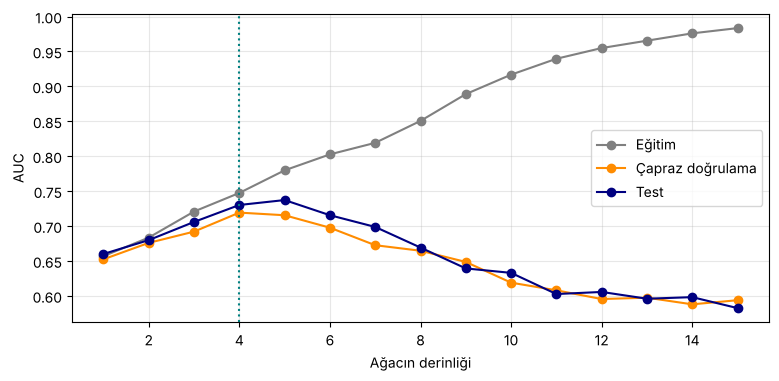

In [3]:
derinlik = range(1, 16); tr_auc, te_auc, cv_auc = [], [], []
for d in derinlik:
    m = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_egt, y_egt)
    tr_auc.append(roc_auc_score(y_egt, m.predict_proba(X_egt)[:, 1]))
    te_auc.append(roc_auc_score(y_tst, m.predict_proba(X_tst)[:, 1]))
    cv_auc.append(cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=0), X_egt, y_egt, cv=kf, scoring='roc_auc').mean())
en_iyi = list(derinlik)[int(np.argmax(cv_auc))]
print(f'Derinlik 15: eğitim AUC {tr_auc[-1]:.3f}, test AUC {te_auc[-1]:.3f}')
print(f'Çapraz doğrulamanın seçtiği derinlik: {en_iyi}, test AUC {te_auc[en_iyi - 1]:.3f}')

plt.figure(figsize=(9, 4))
plt.plot(derinlik, tr_auc, 'o-', color='grey', label='Eğitim')
plt.plot(derinlik, cv_auc, 'o-', color='darkorange', label='Çapraz doğrulama')
plt.plot(derinlik, te_auc, 'o-', color='navy', label='Test')
plt.axvline(en_iyi, color='teal', ls=':'); plt.xlabel('Ağacın derinliği'); plt.ylabel('AUC'); plt.legend(); plt.grid(alpha=0.3); plt.show()

Beklenen: derinlik 15’te eğitim 0,983, test 0,583; seçilen derinlik 4, test 0,730.

### 1.3 Kararsızlık

Eğitim verisinden yerine koyarak 3.000’er gözlemlik 5 örneklem çekip her birine derinliği 4 olan bir ağaç kuruyoruz.

In [4]:
for k in range(5):
    idx = rng.integers(0, 3000, 3000)                       # bootstrap örneklemi
    m = DecisionTreeClassifier(max_depth=4, random_state=0).fit(X_egt[idx], y_egt[idx])
    t = m.tree_
    ikinci = [ADLAR[t.feature[c]] for c in (t.children_left[0], t.children_right[0]) if t.feature[c] >= 0]
    print(f'Örneklem {k+1}: ilk soru {ADLAR[t.feature[0]]} ≤ {t.threshold[0]:.2f}   ikinci düzey: {" · ".join(ikinci):30s}'
          f'test AUC {roc_auc_score(y_tst, m.predict_proba(X_tst)[:, 1]):.3f}')

Örneklem 1: ilk soru Borç/gelir ≤ 0.70   ikinci düzey: Yaş · Yaş                     test AUC 0.719
Örneklem 2: ilk soru Borç/gelir ≤ 0.70   ikinci düzey: Yaş · Çalışma süresi          test AUC 0.732
Örneklem 3: ilk soru Borç/gelir ≤ 0.70   ikinci düzey: Yaş · Yaş                     test AUC 0.743
Örneklem 4: ilk soru Borç/gelir ≤ 0.68   ikinci düzey: Yaş · Önceki gecikme          test AUC 0.712
Örneklem 5: ilk soru Borç/gelir ≤ 0.70   ikinci düzey: Yaş · Çalışma süresi          test AUC 0.716


Beklenen: ilk soru beşinde de borç/gelir (eşik 0,68–0,70), ikinci düzeydeki sorular değişiyor; test AUC’leri 0,712 ile 0,743 arasında.

## 2. Rassal orman (Şekil 3)

500 ağaç; her soruda 6 değişkenden rastgele 2’si deneniyor (`max_features='sqrt'`). Karşılaştırma için her soruda tüm değişkenleri kullanan sürüm (bagging).

Tek ağaç (ortalama) 0.698   bagging 0.793   rassal orman 0.801


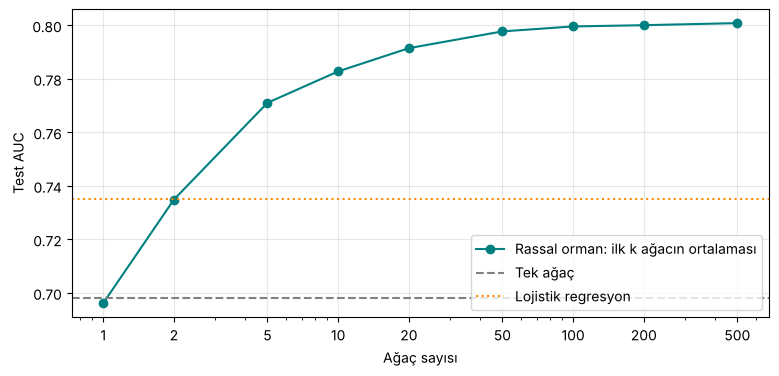

In [5]:
rf = RandomForestClassifier(n_estimators=500, min_samples_leaf=10, max_features='sqrt', random_state=1, n_jobs=-1).fit(X_egt, y_egt)
agac_p = np.array([a.predict_proba(X_tst)[:, 1] for a in rf.estimators_])      # her ağacın olasılıkları
ns = [1, 2, 5, 10, 20, 50, 100, 200, 500]
rf_auc_n = [roc_auc_score(y_tst, agac_p[:k].mean(0)) for k in ns]
tek = np.mean([roc_auc_score(y_tst, agac_p[k]) for k in range(50)])
bag = RandomForestClassifier(n_estimators=500, min_samples_leaf=10, max_features=None, random_state=1, n_jobs=-1).fit(X_egt, y_egt)
print(f'Tek ağaç (ortalama) {tek:.3f}   bagging {roc_auc_score(y_tst, bag.predict_proba(X_tst)[:, 1]):.3f}   '
      f'rassal orman {roc_auc_score(y_tst, rf.predict_proba(X_tst)[:, 1]):.3f}')

plt.figure(figsize=(9, 4)); plt.plot(ns, rf_auc_n, 'o-', color='teal', label='Rassal orman: ilk k ağacın ortalaması')
plt.axhline(tek, color='grey', ls='--', label='Tek ağaç'); plt.axhline(roc_auc_score(y_tst, logit.predict_proba(X_tst)[:, 1]), color='darkorange', ls=':', label='Lojistik regresyon')
plt.xscale('log'); plt.xticks(ns, ns); plt.xlabel('Ağaç sayısı'); plt.ylabel('Test AUC'); plt.legend(); plt.grid(alpha=0.3); plt.show()

Beklenen: tek ağaç 0,698, bagging 0,793, rassal orman 0,801.

## 3. Boosting (Şekil 4 ve 5)

Derinliği 3 olan küçük ağaçlar art arda ekleniyor. İki öğrenme oranını karşılaştırıyoruz, sonra ağaç sayısını eğitim verisi içinde çapraz doğrulamayla seçiyoruz. (Bu hücre en uzun hücredir, yaklaşık 40 saniye.)

Öğrenme oranı 0.05: en iyi 0.807 (93 ağaçta), 600 ağaçta 0.791


Öğrenme oranı 0.5: en iyi 0.792 (8 ağaçta), 600 ağaçta 0.735


Çapraz doğrulamanın seçtiği ağaç sayısı: 100   test AUC 0.807


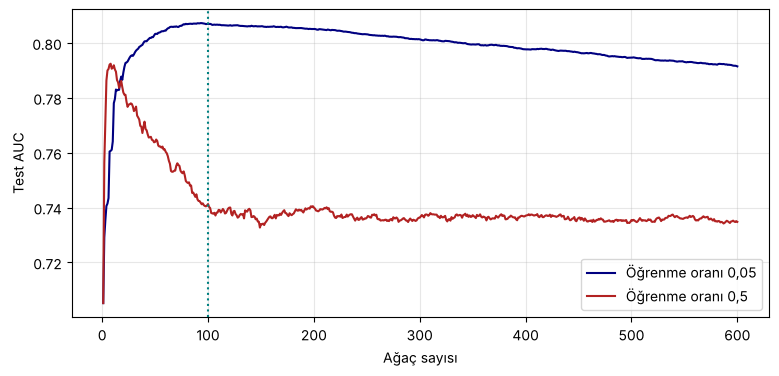

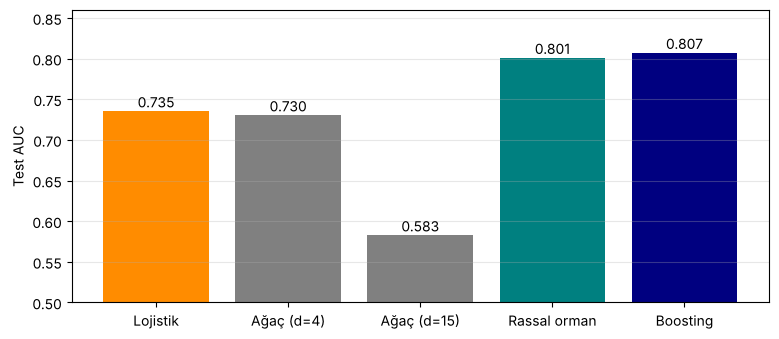

In [6]:
egri = {}
for lr in [0.05, 0.5]:
    m = GradientBoostingClassifier(n_estimators=600, learning_rate=lr, max_depth=3, subsample=0.8, random_state=1).fit(X_egt, y_egt)
    egri[lr] = [roc_auc_score(y_tst, p[:, 1]) for p in m.staged_predict_proba(X_tst)]   # her ağaç eklendikten sonra test AUC
    print(f'Öğrenme oranı {lr}: en iyi {max(egri[lr]):.3f} ({int(np.argmax(egri[lr])) + 1} ağaçta), 600 ağaçta {egri[lr][-1]:.3f}')

adaylar = [50, 100, 200, 300, 400, 600]
cv = {n: cross_val_score(GradientBoostingClassifier(n_estimators=n, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=1),
                         X_egt, y_egt, cv=kf, scoring='roc_auc').mean() for n in adaylar}
n_sec = max(cv, key=cv.get)
gbf = GradientBoostingClassifier(n_estimators=n_sec, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=1).fit(X_egt, y_egt)
print(f'Çapraz doğrulamanın seçtiği ağaç sayısı: {n_sec}   test AUC {roc_auc_score(y_tst, gbf.predict_proba(X_tst)[:, 1]):.3f}')

plt.figure(figsize=(9, 4))
plt.plot(range(1, 601), egri[0.05], color='navy', label='Öğrenme oranı 0,05')
plt.plot(range(1, 601), egri[0.5], color='firebrick', label='Öğrenme oranı 0,5')
plt.axvline(n_sec, color='teal', ls=':'); plt.xlabel('Ağaç sayısı'); plt.ylabel('Test AUC'); plt.legend(); plt.grid(alpha=0.3); plt.show()

sonuc = {'Lojistik': logit, f'Ağaç (d={en_iyi})': DecisionTreeClassifier(max_depth=en_iyi, random_state=0).fit(X_egt, y_egt),
         'Ağaç (d=15)': DecisionTreeClassifier(max_depth=15, random_state=0).fit(X_egt, y_egt), 'Rassal orman': rf, 'Boosting': gbf}
auc = {k: roc_auc_score(y_tst, m.predict_proba(X_tst)[:, 1]) for k, m in sonuc.items()}
plt.figure(figsize=(9, 3.8)); plt.bar(auc.keys(), [v - 0.5 for v in auc.values()], bottom=0.5, color=['darkorange', 'grey', 'grey', 'teal', 'navy'])
for i, v in enumerate(auc.values()): plt.text(i, v + 0.005, f'{v:.3f}', ha='center')
plt.ylim(0.5, 0.86); plt.ylabel('Test AUC'); plt.grid(axis='y', alpha=0.3); plt.show()

Beklenen: öğrenme oranı 0,05’te en iyi 0,807 (93 ağaç); 0,5’te en iyi 0,792 (8 ağaç), 600 ağaçta 0,735. Seçilen ağaç sayısı 100, test AUC 0,807.

## 4. SHAP (Şekil 6–11)

Seçilen boosting modelini 2.000 test başvurusunda açıklıyoruz. SHAP katkıları **log-odds** ölçeğinde: taban + katkılar = modelin log-odds tahmini.

Taban (ortalama başvuran): log-odds -1.93, olasılık %13
Toplama kontrolü: “taban + katkılar” ile modelin log-odds tahmini arasındaki en büyük fark 4.2e-15

Başvuran A: olasılık %62


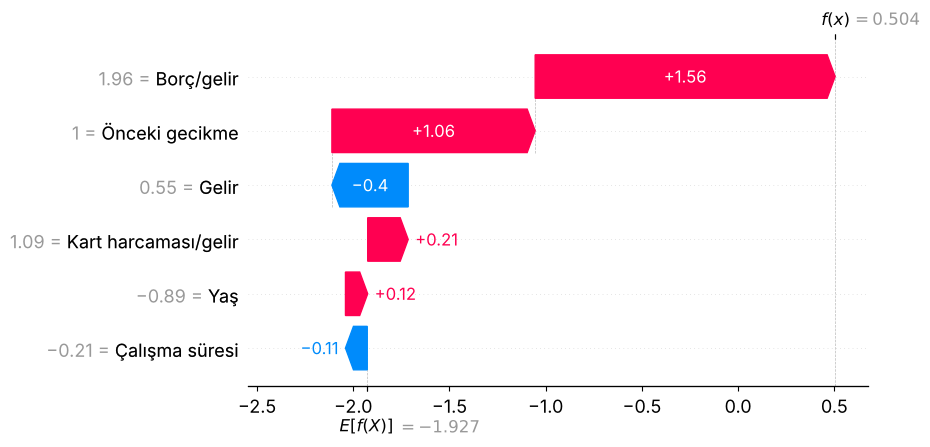


Başvuran B: olasılık %3


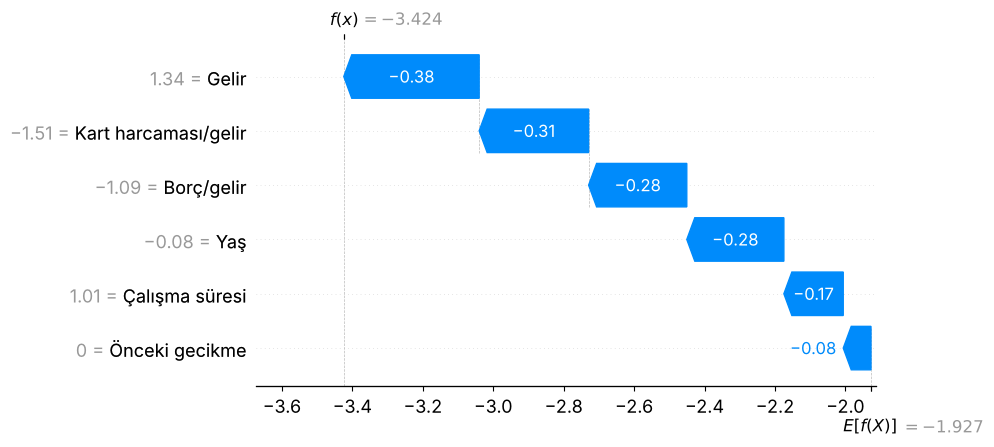

In [7]:
ex = shap.TreeExplainer(gbf)
Xs = X_tst[:2000]
sv = ex.shap_values(Xs)                             # 2.000 × 6 katkı matrisi
taban = float(np.ravel(ex.expected_value)[0])
print(f'Taban (ortalama başvuran): log-odds {taban:.2f}, olasılık %{100/(1+np.exp(-taban)):.0f}')
fark = np.abs(taban + sv.sum(1) - gbf.decision_function(Xs)).max()
print(f'Toplama kontrolü: “taban + katkılar” ile modelin log-odds tahmini arasındaki en büyük fark {fark:.1e}')

# İki başvuran: A (yüksek borç, gecikmeli) ve B (modelin en düşük riskli bulduğu)
i = int(np.where((Xs[:, 1] == 1) & (Xs[:, 0] > 0.9))[0][0])
j = int(np.argmin(gbf.decision_function(Xs)))
for ad, k in [('A', i), ('B', j)]:
    print(f'\nBaşvuran {ad}: olasılık %{100*gbf.predict_proba(Xs[[k]])[0, 1]:.0f}')
    shap.plots.waterfall(shap.Explanation(values=sv[k], base_values=taban, data=Xs[k].round(2), feature_names=ADLAR))

Beklenen: taban -1,93 (olasılık %13); toplama farkı 10⁻¹⁴ düzeyinde. Başvuran A: olasılık %62; borç/gelir +1,56, gecikme +1,06, gelir -0,40. Başvuran B: olasılık %3, bütün katkılar negatif.

Borç/gelir             ortalama |SHAP| 0.45
Yaş                    ortalama |SHAP| 0.33
Gelir                  ortalama |SHAP| 0.29
Çalışma süresi         ortalama |SHAP| 0.24
Önceki gecikme         ortalama |SHAP| 0.20
Kart harcaması/gelir   ortalama |SHAP| 0.20

Lojistik regresyonun yaş katsayısı: -0.06


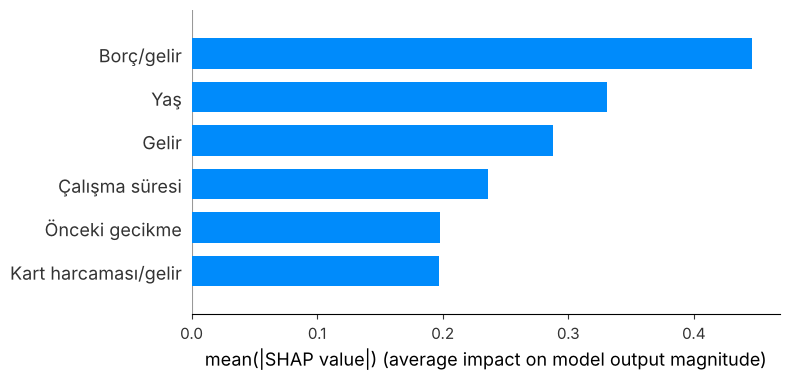

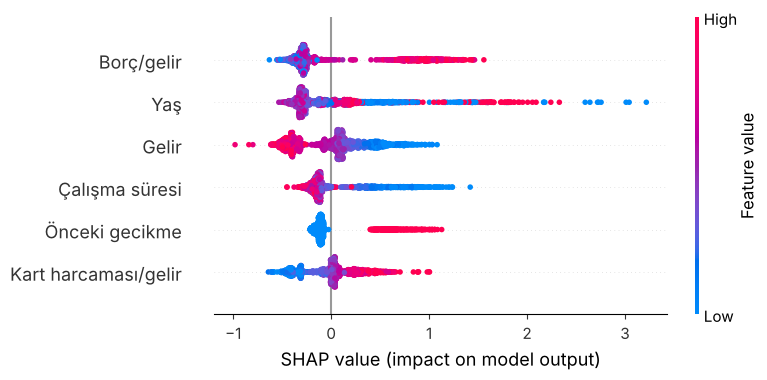

In [8]:
ort = np.abs(sv).mean(0)
for k in np.argsort(-ort): print(f'{ADLAR[k]:22s} ortalama |SHAP| {ort[k]:.2f}')
print(f'\nLojistik regresyonun yaş katsayısı: {logit.coef_[0][5]:.2f}')

shap.summary_plot(sv, Xs, feature_names=ADLAR, plot_type='bar', show=True)   # genel önem
shap.summary_plot(sv, Xs, feature_names=ADLAR, show=True)                    # özet grafik: önem ve yön

Beklenen: borç/gelir 0,45, yaş 0,33 (ikinci sırada); lojistik regresyonun yaş katsayısı -0,06. Doğrusal model U biçimini düz bir çizgiye indiriyor.

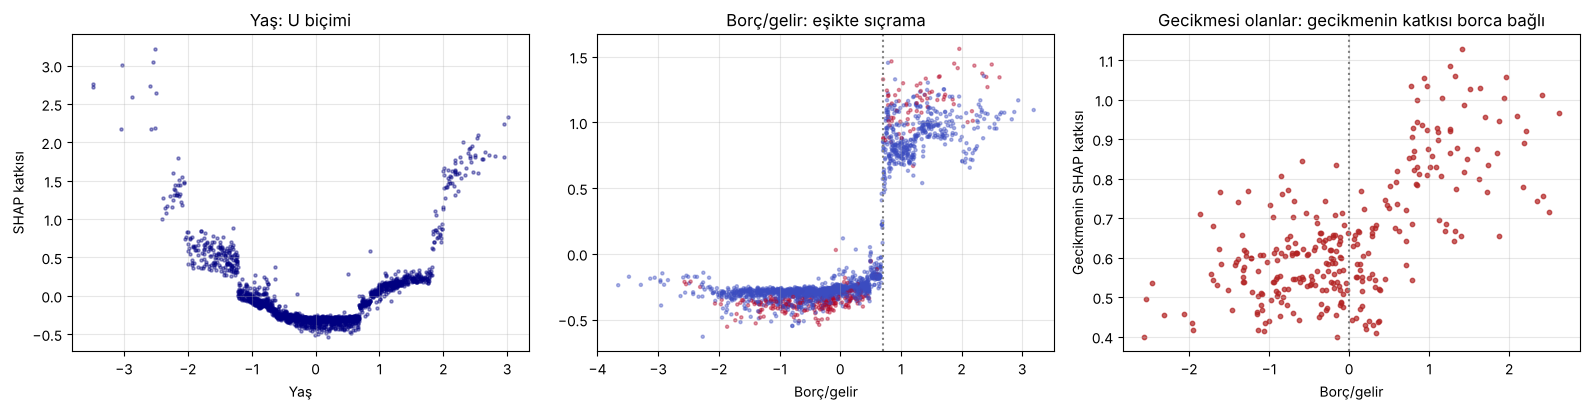

Gecikmenin ortalama katkısı  borç ≤ 0: 0.58   borç > 0: 0.75
Borcun ortalama katkısı  borç < 0,7: -0.29   borç > 0,7: 0.94


In [9]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
axs[0].scatter(Xs[:, 5], sv[:, 5], s=5, alpha=0.4, color='navy'); axs[0].set(title='Yaş: U biçimi', xlabel='Yaş', ylabel='SHAP katkısı')
axs[1].scatter(Xs[:, 0], sv[:, 0], s=5, alpha=0.4, c=Xs[:, 1], cmap='coolwarm'); axs[1].axvline(0.7, ls=':', color='grey')
axs[1].set(title='Borç/gelir: eşikte sıçrama', xlabel='Borç/gelir')
g = Xs[:, 1] == 1
axs[2].scatter(Xs[g, 0], sv[g, 1], s=10, alpha=0.7, color='firebrick'); axs[2].axvline(0, ls=':', color='grey')
axs[2].set(title='Gecikmesi olanlar: gecikmenin katkısı borca bağlı', xlabel='Borç/gelir', ylabel='Gecikmenin SHAP katkısı')
for a in axs: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f'Gecikmenin ortalama katkısı  borç ≤ 0: {sv[g & (Xs[:, 0] <= 0), 1].mean():.2f}   borç > 0: {sv[g & (Xs[:, 0] > 0), 1].mean():.2f}')
print(f'Borcun ortalama katkısı  borç < 0,7: {sv[Xs[:, 0] < 0.7, 0].mean():.2f}   borç > 0,7: {sv[Xs[:, 0] > 0.7, 0].mean():.2f}')

Beklenen: gecikmenin katkısı 0,58 ve 0,75; borcun katkısı -0,29 ve 0,94.

**Hatırlatma:** SHAP modelin tahminini açıklar, nedensel etki göstermez. İlişkili değişkenler (yaş ve çalışma süresi) katkıyı paylaşabilir.